# DeepSeek: сравнение SP и TP в BF16, FP16 и FP32

Три последовательных независимых запуска для первого, среднего и последнего слоёв, с активациями и градиентами.
Каждый запуск загружает новую модель и создаёт новый bridge. После запуска модель освобождается перед загрузкой следующей.
Результаты сохраняются на CPU в `results`; заголовки графиков содержат название модели и точность.

Для каждой включённой точности создаётся отдельный run в эксперименте MLflow.
В Artifacts сохраняются `pruning/result.pt` (сравнение, оба CPU-трейса и входные токены) и графики.
MLflow использует текущие настройки подключения (в том числе `MLFLOW_TRACKING_URI`); без них — локальное хранилище.
Для запуска нужен установленный пакет `mlflow`.


In [1]:
import gc
import sys
import tempfile
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pruning_lens").is_dir())
sys.path.insert(0, str(ROOT))

import mlflow
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformer_lens.model_bridge import TransformerBridge
from lora_transfer_pruning.core.prune_task_type import GroupPruneTask, ModelPruneTask
from pruning_lens.usecase.compare_pruned_models_usecase import ComparePrunedModelsUsecase
from pruning_lens.core.compairing_trace_visualizer import CompairingTraceVisualizer

MODEL = "deepseek-ai/DeepSeek-V2-Lite-Chat"
DEVICE = "cuda:2"
PRECISIONS = [("BF16", torch.bfloat16), ("FP16", torch.float16)] #("FP32", torch.float32) - cant load in fp32

# Release model references left by the previous version of this notebook.
model = bridge = None
gc.collect()
torch.cuda.empty_cache()
SEED = 0

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL, trust_remote_code=False)
tokens = tokenizer(
    "The attention mechanism allows a language model to use information from earlier tokens.",
    return_tensors="pt",
).input_ids.to(DEVICE)


In [3]:
def load_model_and_compare_pipeline(dtype):
    model = bridge = None
    try:
        torch.manual_seed(SEED)
        model = AutoModelForCausalLM.from_pretrained(
            MODEL, trust_remote_code=False, device_map={"": DEVICE},
            dtype=dtype, attn_implementation="eager",
        ).eval()
        bridge = TransformerBridge.boot_transformers(MODEL, hf_model=model, dtype=dtype)
        n_layers = len(bridge.blocks)
        layers = [0, n_layers // 2, n_layers - 1]
        
        
        mlflow.log_params({"layers": layers, "pruned_q_rows": [1, 2, 130]})
        
        
        prune_task = ModelPruneTask({
            f"blocks.{layer}.attn.q_proj": GroupPruneTask(cols=None, rows=[1, 2, 130])
            for layer in layers
        })
        return ComparePrunedModelsUsecase.compare_transfer_and_torch_prunings_on_layers(
            bridge, tokens, prune_task, layers=layers, compute_gradient=True,
        )
    finally:
        # Drop both owners, collect cycles, then release unused CUDA allocations.
        del bridge, model
        gc.collect()
        torch.cuda.empty_cache()


In [4]:
import os
mlflow.set_tracking_uri("http://172.19.0.1:5000")
mlFlowClient = mlflow.MlflowClient()

from dotenv import load_dotenv

load_dotenv()

MLFLOW_EXPERIMENT = "deepseek-pruning-comparator"
mlflow.set_experiment(MLFLOW_EXPERIMENT)
print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")


MLflow tracking URI: http://172.19.0.1:5000



======================== deepseek-ai/DeepSeek-V2-Lite-Chat · BF16 ========================


Loading weights:   0%|          | 0/351 [00:00<?, ?it/s]

/glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch_pruning/dependency/graph.py:390: UserWarning: Unwrapped parameters detected: ['model.layers.1._original_component.mlp._original_component.experts.gate_up_proj', 'model.layers.1._original_component.post_attention_layernorm._original_component.weight', 'model.layers.4._original_component.self_attn._original_component.kv_a_layernorm._original_component.weight', 'model.layers.4._original_component.post_attention_layernorm._original_component.weight', 'model.layers.19._original_component.self_attn._original_component.kv_a_layernorm._original_component.weight', 'model.layers.22._original_component.mlp._original_component.experts.down_proj', 'model.layers.2._original_component.mlp._original_component.experts.gate_up_proj', 'model.layers.3._original_component.post_attention_layernorm._original_component.weight', 'model.layers.10._original_component.mlp._original_component.experts.gate_up_proj', 'model.layers.17._origin

SETUP FUNCTION MSG: module=blocks.0.attn.q_proj DeepSeek indices from group:
  q_local=[1, 2, 130, 131]
  q_nope=[1, 2]
  q_rope=[2, 3]
  kv_a.out=[514.0, 515.0]
  kv_b.out=[1, 2, 257, 258, 513, 514, 769, 770, 1025, 1026, 1281, 1282, 1537, 1538, 1793, 1794, 2049, 2050, 2305, 2306, 2561, 2562, 2817, 2818, 3073, 3074, 3329, 3330, 3585, 3586, 3841, 3842]
  kv_b.in=[]
  o_proj.in=[]
SETUP FUNCTION MSG: module=blocks.13.attn.q_proj DeepSeek indices from group:
  q_local=[1, 2, 130, 131]
  q_nope=[1, 2]
  q_rope=[2, 3]
  kv_a.out=[514.0, 515.0]
  kv_b.out=[1, 2, 257, 258, 513, 514, 769, 770, 1025, 1026, 1281, 1282, 1537, 1538, 1793, 1794, 2049, 2050, 2305, 2306, 2561, 2562, 2817, 2818, 3073, 3074, 3329, 3330, 3585, 3586, 3841, 3842]
  kv_b.in=[]
  o_proj.in=[]
SETUP FUNCTION MSG: module=blocks.26.attn.q_proj DeepSeek indices from group:
  q_local=[1, 2, 130, 131]
  q_nope=[1, 2]
  q_rope=[2, 3]
  kv_a.out=[514.0, 515.0]
  kv_b.out=[1, 2, 257, 258, 513, 514, 769, 770, 1025, 1026, 1281, 1282, 

/glazkov-dev/LoRa-Transfer-Pruning/pruning_lens/usecase/compare_pruned_models_usecase.py:101: UserWarning: Skipping disabled capture hooks: blocks.0.hook_mlp_in (use_hook_mlp_in=False), blocks.13.hook_mlp_in (use_hook_mlp_in=False), blocks.26.hook_mlp_in (use_hook_mlp_in=False)
  names_filter = HookNamesFilter.filter(model,


[00] blocks.0.attn.q_proj.hook_in
     FWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=9.918e-05 mean_abs=7.414e-06 rmse=1.168e-05 rel_l2=5.168e-02 abs_l2=1.978e-03
[01] blocks.0.attn.q_proj.hook_out
     FWD    OK            shape=(1, 14, 3072) compared=43008 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    DIFF          shape=(1, 14, 3072) compared=43008 max_abs=2.594e-04 mean_abs=2.159e-06 rmse=6.052e-06 rel_l2=5.138e-02 abs_l2=1.255e-03
[02] blocks.0.attn.kv_a_proj_with_mqa.hook_in
     FWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    DIFF          shape=(1, 14, 2048) compared=28672 max_abs=4.120e-04 mean_abs=2.276e-05 rmse=3.852e-05 rel_l2=4.757e-02 abs_l2=6.523e-03
[03

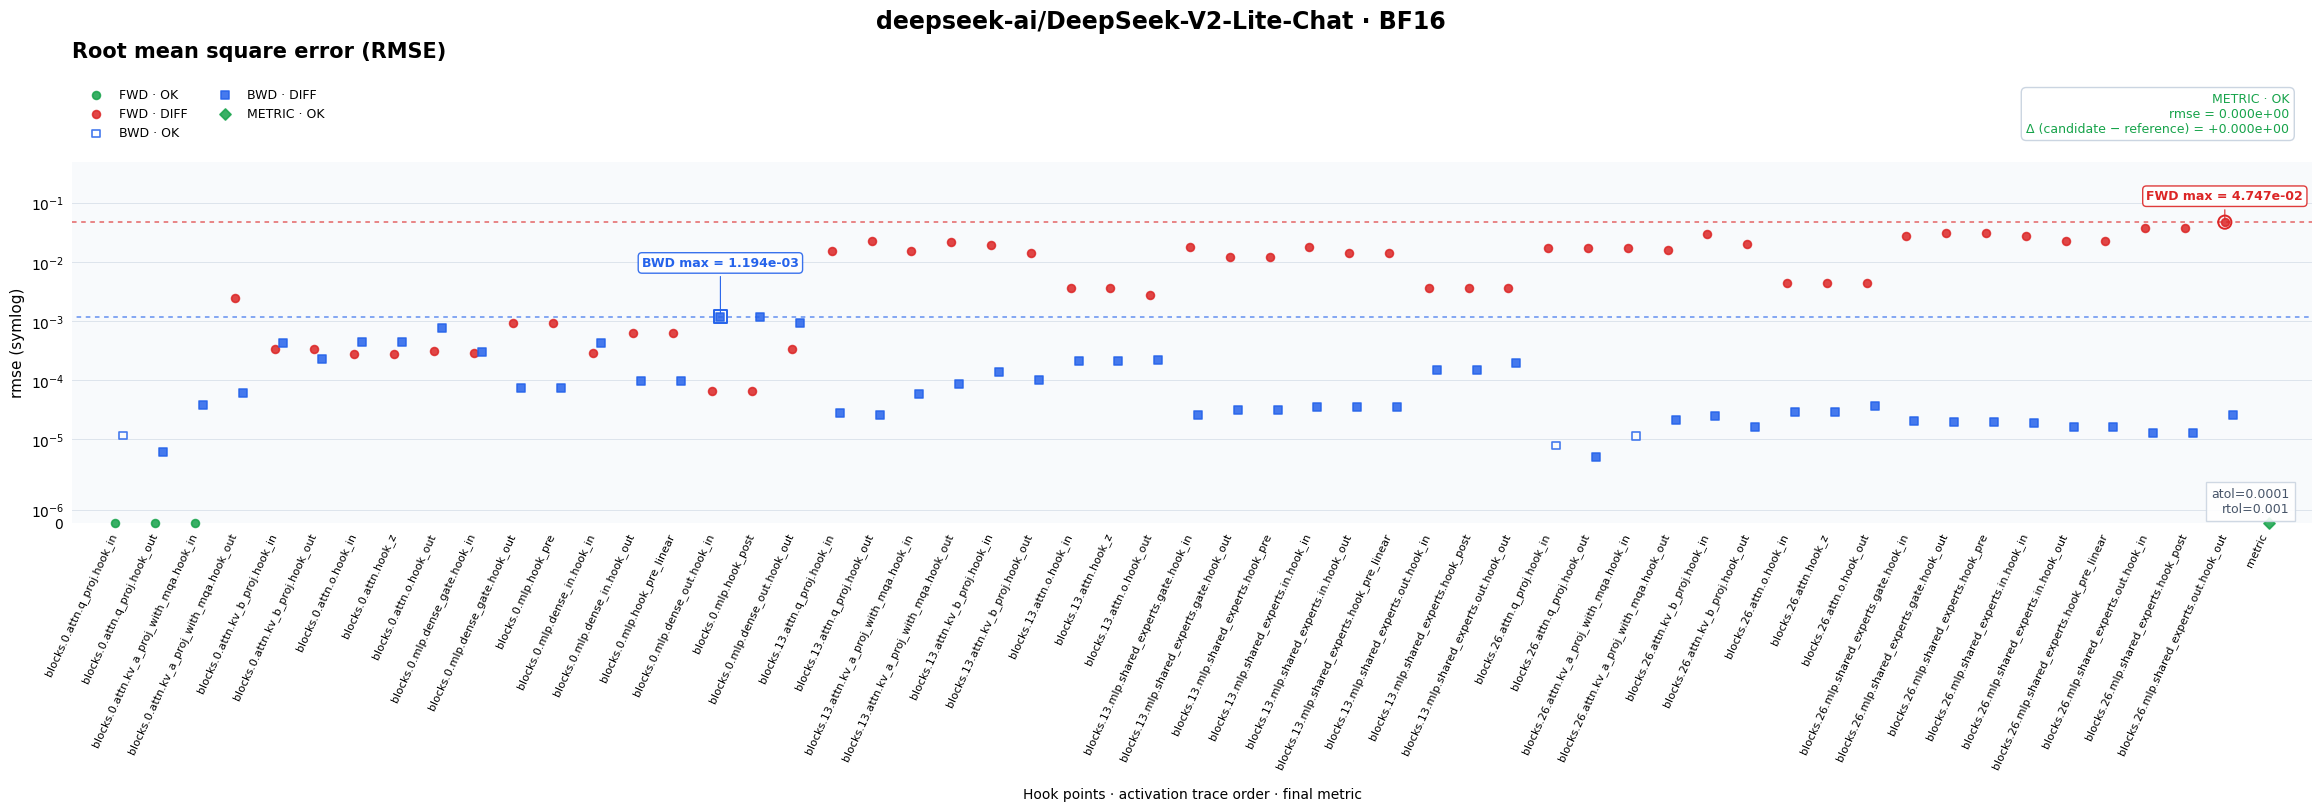

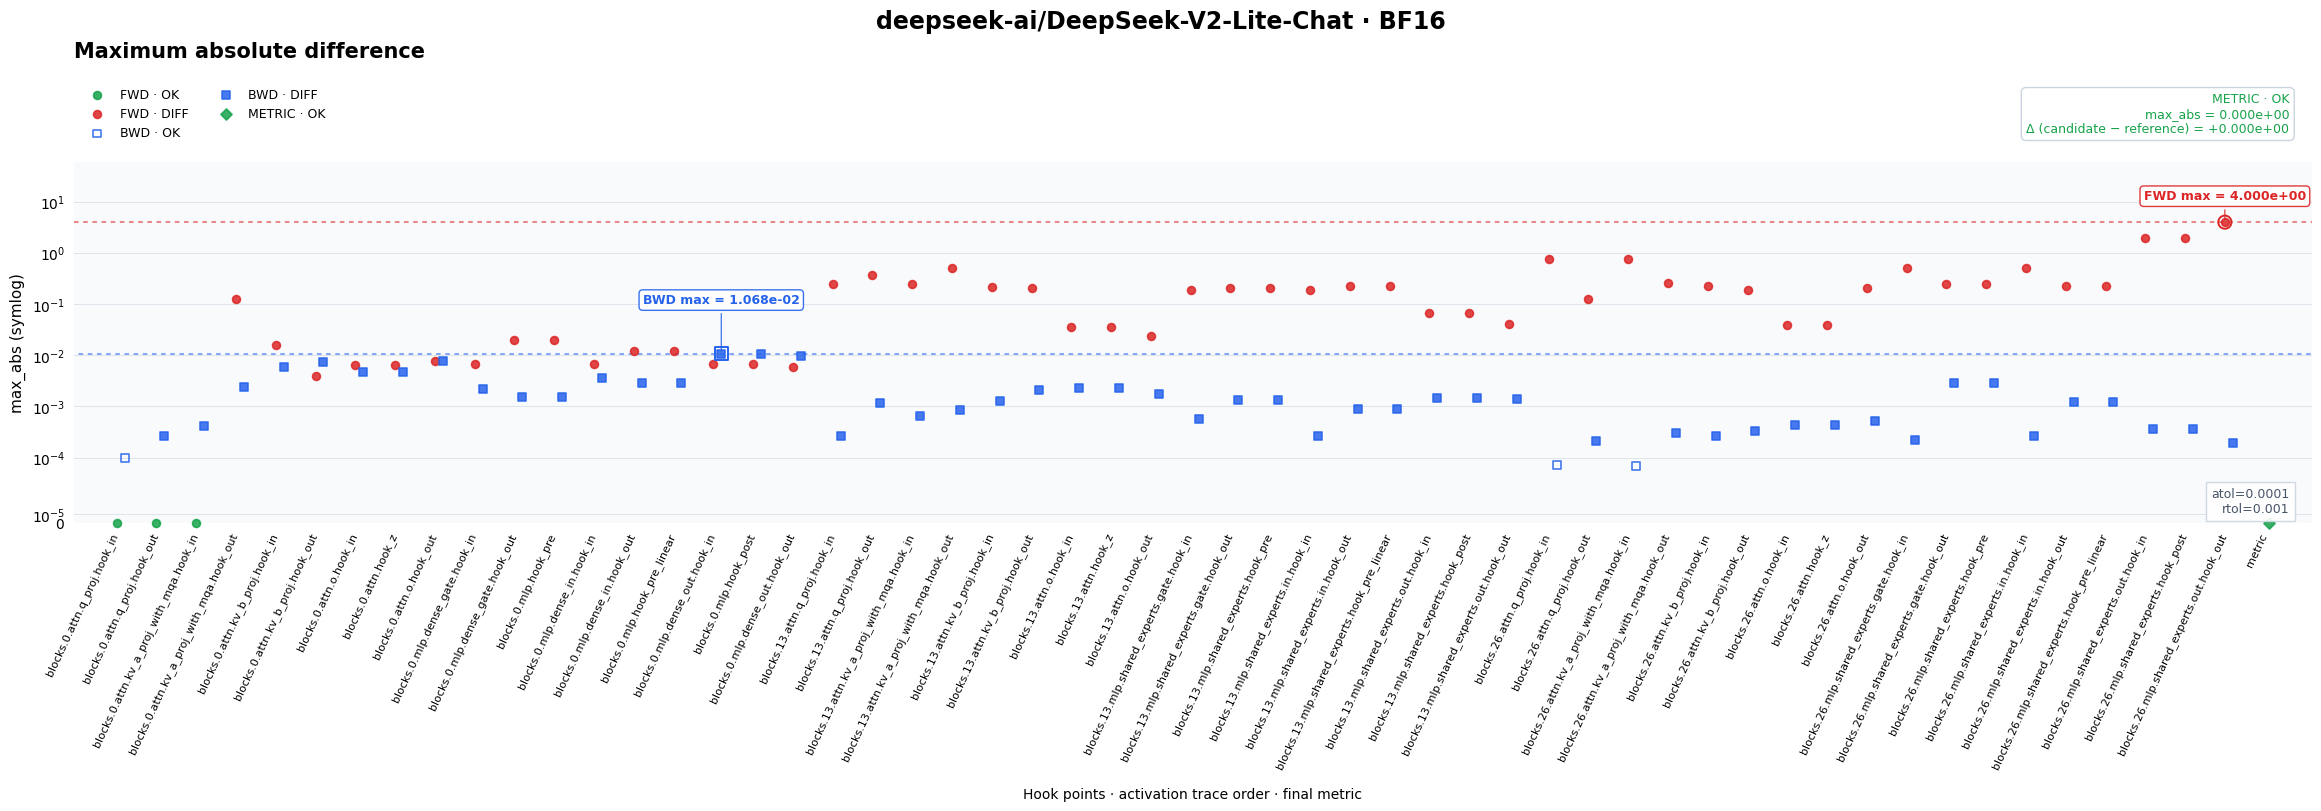

🏃 View run DeepSeek-V2-Lite-Chat-BF16 at: http://172.19.0.1:5000/#/experiments/76/runs/4d8d6da633494e3da37fdc9c61df7341
🧪 View experiment at: http://172.19.0.1:5000/#/experiments/76

======================== deepseek-ai/DeepSeek-V2-Lite-Chat · FP16 ========================


Loading weights:   0%|          | 0/351 [00:00<?, ?it/s]

/glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch_pruning/dependency/graph.py:390: UserWarning: Unwrapped parameters detected: ['model.layers.9._original_component.mlp._original_component.experts.gate_up_proj', 'model.layers.12._original_component.mlp._original_component.experts.gate_up_proj', 'model.layers.19._original_component.input_layernorm._original_component.weight', 'model.layers.19._original_component.post_attention_layernorm._original_component.weight', 'model.layers.20._original_component.self_attn._original_component.kv_a_layernorm._original_component.weight', 'model.layers.3._original_component.input_layernorm._original_component.weight', 'model.layers.0._original_component.self_attn._original_component.kv_a_layernorm._original_component.weight', 'model.layers.11._original_component.self_attn._original_component.kv_a_layernorm._original_component.weight', 'model.layers.15._original_component.input_layernorm._original_component.weight', 'model.laye

SETUP FUNCTION MSG: module=blocks.0.attn.q_proj DeepSeek indices from group:
  q_local=[1, 2, 130, 131]
  q_nope=[1, 2]
  q_rope=[2, 3]
  kv_a.out=[514.0, 515.0]
  kv_b.out=[1, 2, 257, 258, 513, 514, 769, 770, 1025, 1026, 1281, 1282, 1537, 1538, 1793, 1794, 2049, 2050, 2305, 2306, 2561, 2562, 2817, 2818, 3073, 3074, 3329, 3330, 3585, 3586, 3841, 3842]
  kv_b.in=[]
  o_proj.in=[]
SETUP FUNCTION MSG: module=blocks.13.attn.q_proj DeepSeek indices from group:
  q_local=[1, 2, 130, 131]
  q_nope=[1, 2]
  q_rope=[2, 3]
  kv_a.out=[514.0, 515.0]
  kv_b.out=[1, 2, 257, 258, 513, 514, 769, 770, 1025, 1026, 1281, 1282, 1537, 1538, 1793, 1794, 2049, 2050, 2305, 2306, 2561, 2562, 2817, 2818, 3073, 3074, 3329, 3330, 3585, 3586, 3841, 3842]
  kv_b.in=[]
  o_proj.in=[]
SETUP FUNCTION MSG: module=blocks.26.attn.q_proj DeepSeek indices from group:
  q_local=[1, 2, 130, 131]
  q_nope=[1, 2]
  q_rope=[2, 3]
  kv_a.out=[514.0, 515.0]
  kv_b.out=[1, 2, 257, 258, 513, 514, 769, 770, 1025, 1026, 1281, 1282, 

/glazkov-dev/LoRa-Transfer-Pruning/pruning_lens/usecase/compare_pruned_models_usecase.py:101: UserWarning: Skipping disabled capture hooks: blocks.0.hook_mlp_in (use_hook_mlp_in=False), blocks.13.hook_mlp_in (use_hook_mlp_in=False), blocks.26.hook_mlp_in (use_hook_mlp_in=False)
  names_filter = HookNamesFilter.filter(model,


[00] blocks.0.attn.q_proj.hook_in
     FWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=1.431e-05 mean_abs=1.140e-06 rmse=1.800e-06 rel_l2=8.021e-03 abs_l2=3.048e-04
[01] blocks.0.attn.q_proj.hook_out
     FWD    OK            shape=(1, 14, 3072) compared=43008 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    OK            shape=(1, 14, 3072) compared=43008 max_abs=3.242e-05 mean_abs=3.390e-07 rmse=9.314e-07 rel_l2=7.943e-03 abs_l2=1.932e-04
[02] blocks.0.attn.kv_a_proj_with_mqa.hook_in
     FWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=6.104e-05 mean_abs=3.585e-06 rmse=6.471e-06 rel_l2=8.030e-03 abs_l2=1.096e-03
[03

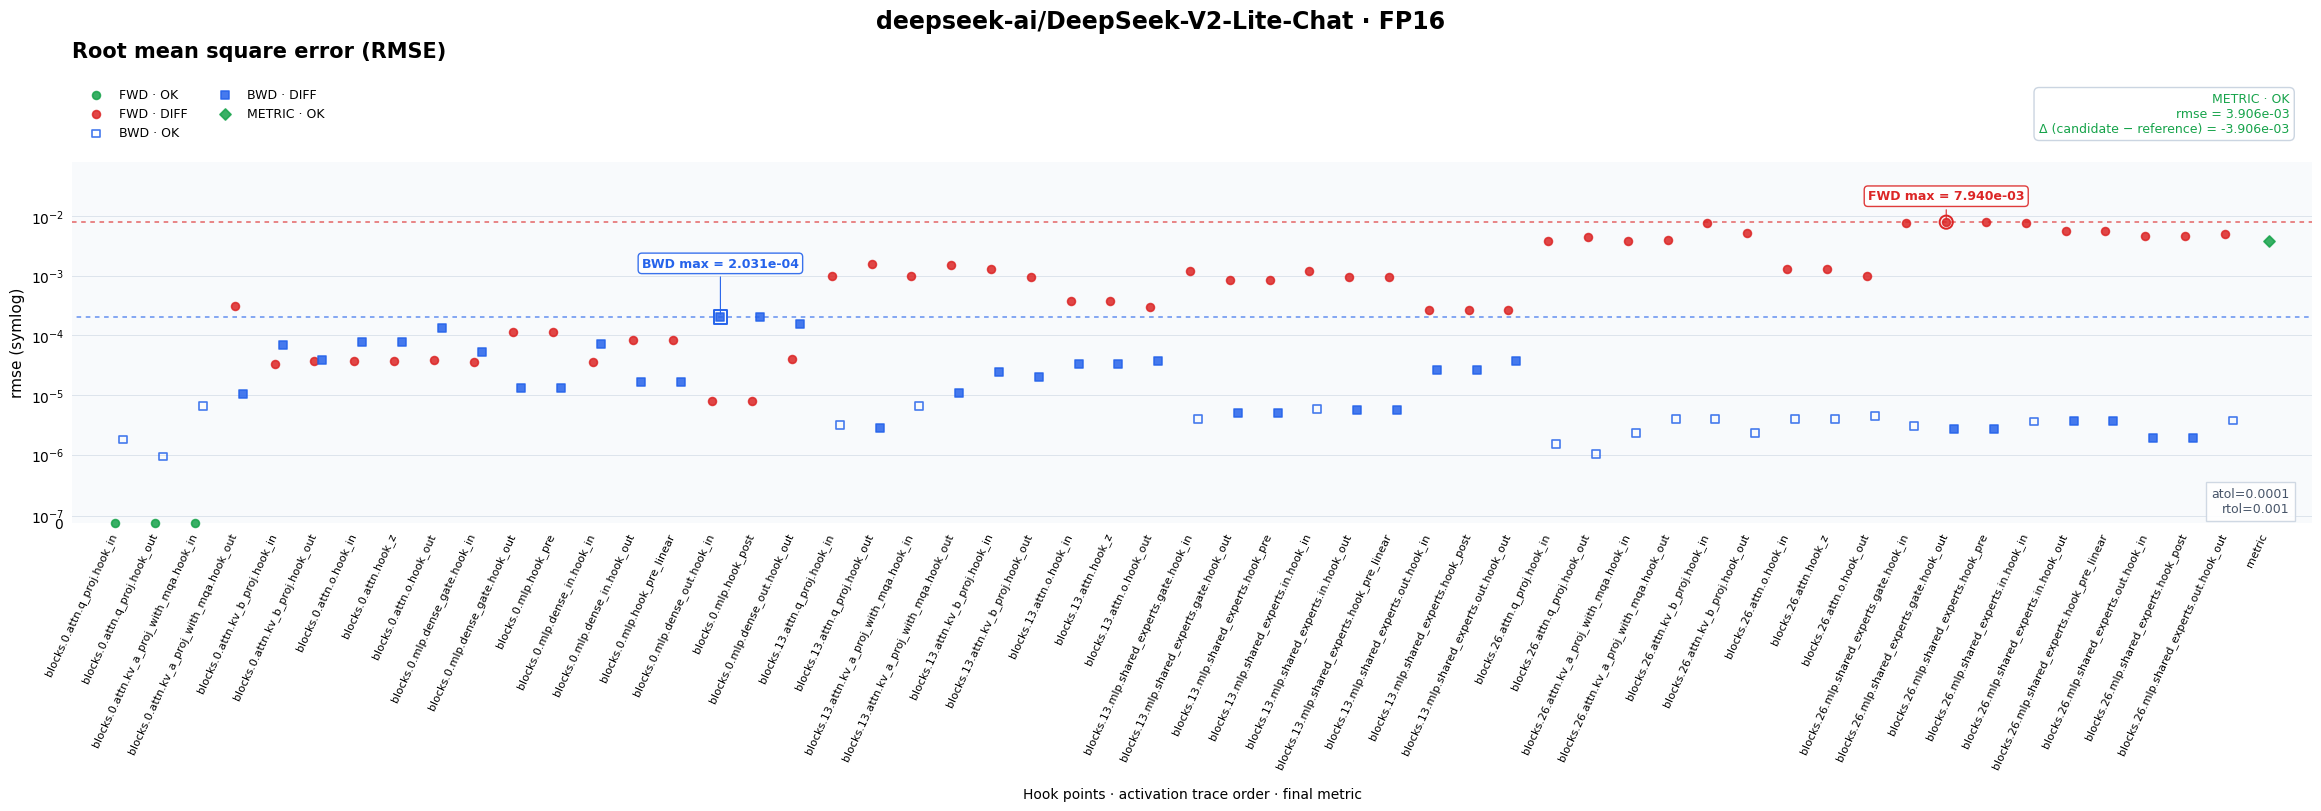

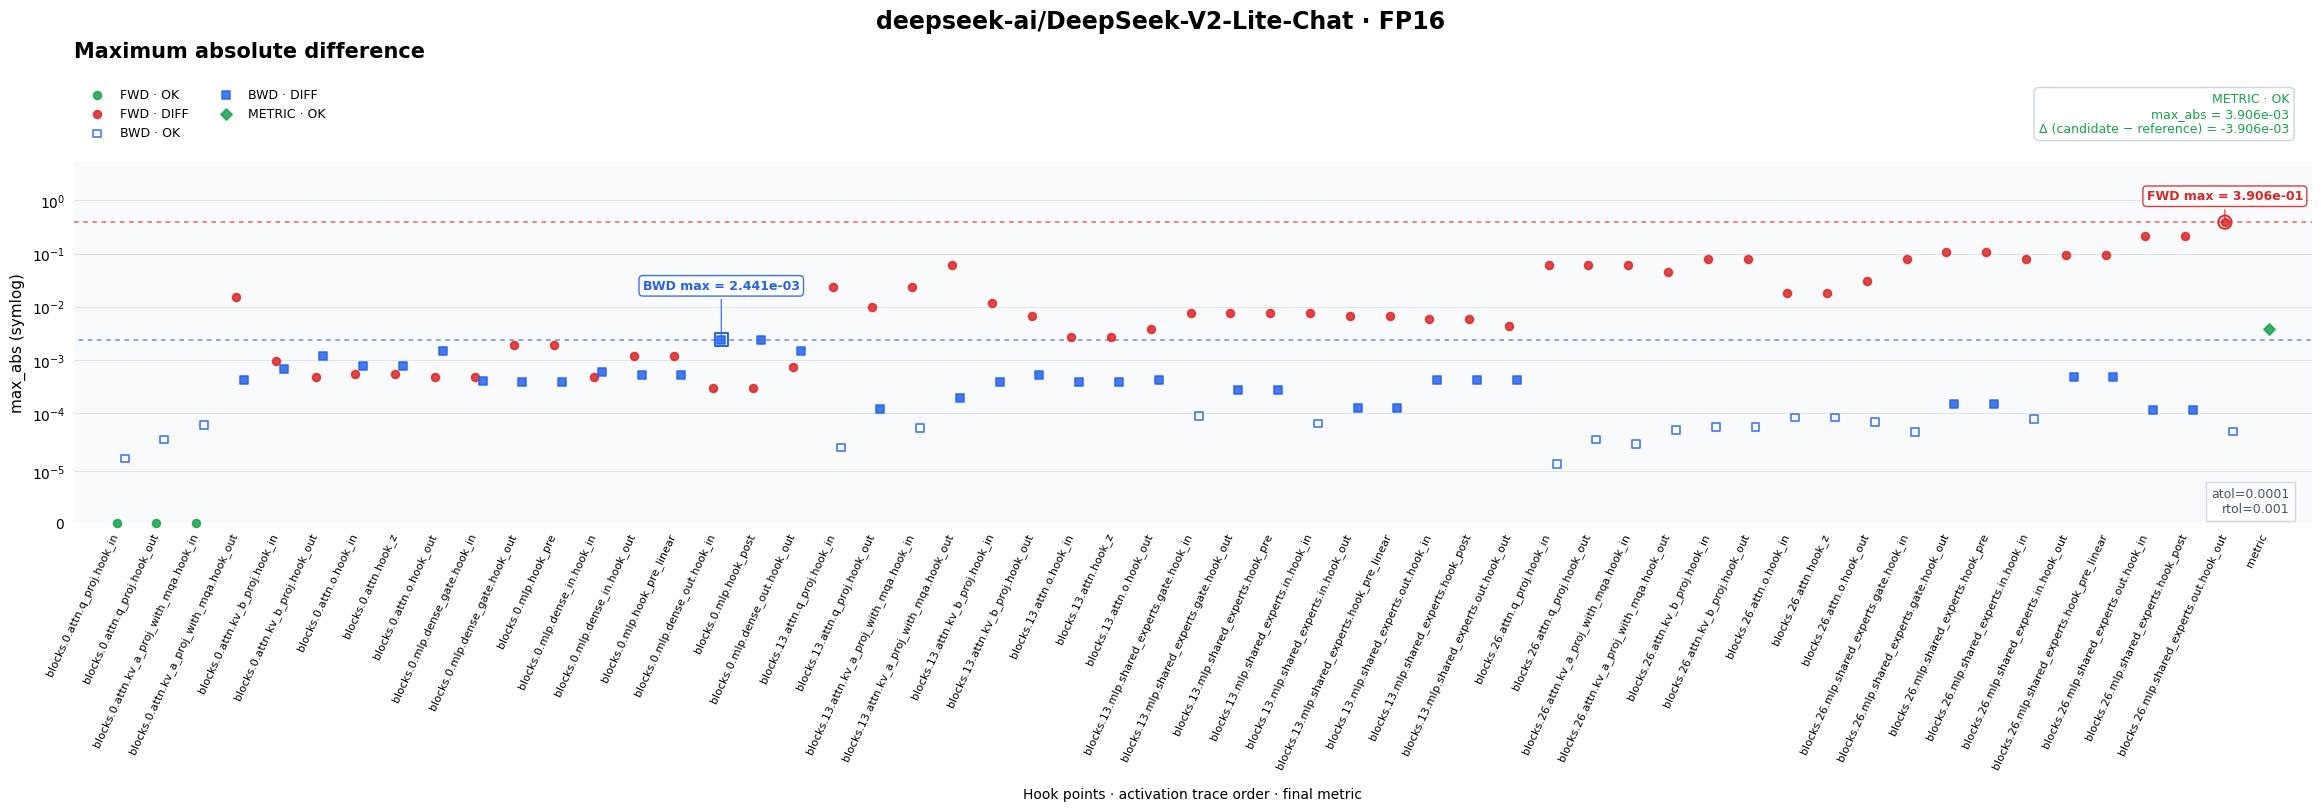

🏃 View run DeepSeek-V2-Lite-Chat-FP16 at: http://172.19.0.1:5000/#/experiments/76/runs/e9995d81517b4c548e833882184d94bb
🧪 View experiment at: http://172.19.0.1:5000/#/experiments/76


In [5]:
results = {}
for precision, dtype in PRECISIONS:
    print(f"\n{'=' * 24} {MODEL} · {precision} {'=' * 24}")
    with mlflow.start_run(run_name=f"{MODEL.rsplit('/', 1)[-1]}-{precision}") as run:
        mlflow.log_params({
            "model": MODEL,
            "precision": precision,
            "seed": SEED,
            "compute_gradient": True,
            "attn_implementation": "eager",
        })
        compairing_trace, sim_prune_trace, tp_trace = load_model_and_compare_pipeline(dtype)
        results[precision] = {
            "comparison": compairing_trace,
            "sim_prune_trace": sim_prune_trace,
            "tp_trace": tp_trace,
        }
        mlflow.log_params({
            "compairing_trace.atol": compairing_trace.atol,
            "compairing_trace.rtol": compairing_trace.rtol,
        })
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "result.pt"
            torch.save({
                **results[precision],
            }, path)
            
            artifact_path="pruning_traces"
            mlflow.log_artifact(str(path), artifact_path="traces")
        print(f"Saved: s3://mlflow/{run.info.experiment_id}/runs/{run.info.run_id}/artifact/traces/result.pt")

        figures = CompairingTraceVisualizer.plot_metrics(
            compairing_trace, ["rmse", "max_abs"], title=f"{MODEL} · {precision}",
        )
        try:
            pass
            for name, figure in figures.items():
                mlflow.log_figure(figure, f"figures/{name}.png")
        finally:
            for figure in figures.values():
                plt.close(figure)


In [6]:
# import pyplot as plt
# compairing_trace.activations['blocks.0.attn.o.hook_out'].difference.reshape(-1)